# Entrenamiento de CNN con Transfer Learning
## Objetivos
- Baseline simple con transfer learning usando ResNet18 o VGG16,
- Entrenar solo la cabeza clasificadora (fine-tuning parcial),
- Hacer fine-tuning parcial o total según resultados,
- Guardar métricas por época,
- Guardar el mejor modelo según validación,
- Matriz de confusión y reporte de clasificación final,
- Accuracy, precision, recall y F1-score.

In [1]:
# Importaciones
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix

from vasijas.paths import ProjectPaths
from vasijas.config import load_config
from vasijas.entrenamiento_cnn import (
    ConfiguracionSplitDataset,
    ConfiguracionTransformacionesImagen,
    crear_dataloaders_imagen,
    crear_modelo_transfer_learning,
    crear_optimizador_adam,
    describir_dispositivo,
    entrenar_modelo,
    seleccionar_dispositivo_procesamiento,
    validar_modelo,
)

In [2]:
# Configuracion general
CONFIG = load_config()
PATHS = ProjectPaths.from_root(CONFIG.project_root)

DEVICE = seleccionar_dispositivo_procesamiento()
print(describir_dispositivo(DEVICE))

Dispositivo seleccionado para procesamiento: CUDA - NVIDIA GeForce GTX 1650


In [3]:
# Parámetros

# Entrenamiento
BATCH_SIZE = 16
EPOCHS = 30
LR = 1e-3

# Preprocesamiento
IMG_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# Aumentación de datos
FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.7, 1.0)
ROTATION_DEGREES = 15
PIXEL_FILL = (255, 255, 255)

# Reproducibilidad
SEED = 42

# Modelo
MODEL_NAME = "resnet18"

# Ruta de datos
DATA_DIR = PATHS.DATA_CUADRADOS

In [4]:
# Transformaciones y dataloaders
config_transformaciones = ConfiguracionTransformacionesImagen(
    tamano_imagen=IMG_SIZE,
    probabilidad_flip=FLIP_PROBABILITY,
    intervalo_escalado=SCALING_FACTOR_INTERVAL,
    grados_rotacion=ROTATION_DEGREES,
    relleno_pixeles=PIXEL_FILL,
    media_normalizacion=IMAGENET_MEAN,
    desvio_normalizacion=IMAGENET_STD,
)
config_split = ConfiguracionSplitDataset(semilla=SEED)

dataloaders = crear_dataloaders_imagen(
    data_dir=DATA_DIR,
    batch_size=BATCH_SIZE,
    configuracion_transformaciones=config_transformaciones,
    configuracion_split=config_split,
)

train_loader = dataloaders.train
val_loader = dataloaders.val
test_loader = dataloaders.test
class_names = dataloaders.class_names
NUM_CLASSES = dataloaders.num_classes

print("Clases:", class_names)
print(
    f"Split -> train: {len(train_loader.dataset)}, "
    f"val: {len(val_loader.dataset)}, "
    f"test: {len(test_loader.dataset)}"
)

Clases: ['clase01', 'clase02', 'clase03', 'clase04', 'clase05', 'clase06', 'clase07', 'clase08', 'clase09', 'clase10', 'clase11', 'sin_clase']
Split -> train: 869, val: 186, test: 187


In [5]:
# Visualización rápida (sanity check)
def show_batch(loader):
    images, labels = next(iter(loader))
    images = images[:8]
    labels = labels[:8]

    fig, axes = plt.subplots(1, 8, figsize=(16, 3))
    for i, ax in enumerate(axes):
        img = images[i].permute(1, 2, 0).numpy()
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(class_names[labels[i]])
        ax.axis("off")


model = crear_modelo_transfer_learning(
    nombre_modelo=MODEL_NAME,
    num_classes=NUM_CLASSES,
    dispositivo=DEVICE,
)

In [6]:
# Criterio y optimizador
criterion = nn.CrossEntropyLoss()
optimizer = crear_optimizador_adam(model, learning_rate=LR)

In [7]:
# Loop de entrenamiento
def imprimir_metricas_epoch(metrica):
    print(f"Epoch {metrica.epoch}/{EPOCHS}")
    print(
        f"Train Loss: {metrica.train_loss:.4f} | Train Acc: {metrica.train_accuracy:.4f}"
    )
    print(f"Val Loss: {metrica.val_loss:.4f} | Val Acc: {metrica.val_accuracy:.4f}")
    print(f"Tiempo de epoch: {metrica.duracion}")


historial = entrenar_modelo(
    modelo=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterio=criterion,
    optimizador=optimizer,
    dispositivo=DEVICE,
    epochs=EPOCHS,
    al_finalizar_epoch=imprimir_metricas_epoch,
)

train_losses = historial.train_losses
val_losses = historial.val_losses
train_accs = historial.train_accuracies
val_accs = historial.val_accuracies

Epoch 1/30
Train Loss: 1.8938 | Train Acc: 0.4039
Val Loss: 1.8868 | Val Acc: 0.4946
Tiempo de epoch: 0:00:22.711325


Epoch 2/30
Train Loss: 1.4766 | Train Acc: 0.5432
Val Loss: 1.6054 | Val Acc: 0.4892
Tiempo de epoch: 0:00:20.940870


Epoch 3/30
Train Loss: 1.3374 | Train Acc: 0.5834
Val Loss: 1.5481 | Val Acc: 0.4946
Tiempo de epoch: 0:00:20.595296


Epoch 4/30
Train Loss: 1.2857 | Train Acc: 0.5903
Val Loss: 1.4028 | Val Acc: 0.5753
Tiempo de epoch: 0:00:21.586170


Epoch 5/30
Train Loss: 1.2388 | Train Acc: 0.5972
Val Loss: 1.3959 | Val Acc: 0.5753
Tiempo de epoch: 0:00:20.901950


Epoch 6/30
Train Loss: 1.1440 | Train Acc: 0.6375
Val Loss: 1.3652 | Val Acc: 0.5538
Tiempo de epoch: 0:00:21.030815


... (20 outputs left out)

Epoch 27/30
Train Loss: 0.9070 | Train Acc: 0.7008
Val Loss: 1.0589 | Val Acc: 0.6613
Tiempo de epoch: 0:00:20.868321


Epoch 28/30
Train Loss: 0.9158 | Train Acc: 0.6974
Val Loss: 1.1175 | Val Acc: 0.5914
Tiempo de epoch: 0:00:21.172280


Epoch 29/30
Train Loss: 0.8604 | Train Acc: 0.7296
Val Loss: 1.1609 | Val Acc: 0.5645
Tiempo de epoch: 0:00:20.843300


Epoch 30/30
Train Loss: 0.8475 | Train Acc: 0.7296
Val Loss: 1.1702 | Val Acc: 0.5968
Tiempo de epoch: 0:00:21.023732


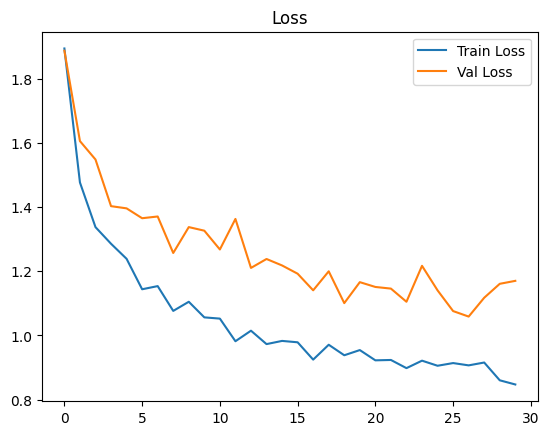

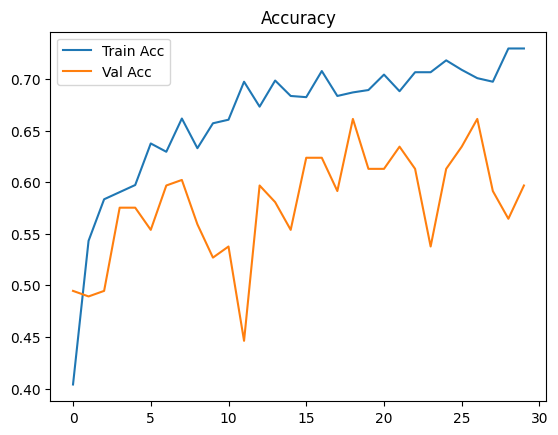

In [8]:
# 7. Curvas de 03.entrenamiento
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Loss")
plt.show()

plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.legend()
plt.title("Accuracy")
plt.show()

Test Acc: 0.6257
              precision    recall  f1-score   support

     clase01       0.00      0.00      0.00         4
     clase02       0.50      0.29      0.36         7
     clase03       0.67      0.18      0.29        11
     clase04       0.00      0.00      0.00         1
     clase05       0.67      0.89      0.76         9
     clase06       1.00      0.29      0.44         7
     clase07       0.67      0.29      0.40         7
     clase08       0.54      0.95      0.69        42
     clase09       0.00      0.00      0.00         3
     clase10       0.70      0.98      0.82        54
     clase11       0.73      0.44      0.55        18
   sin_clase       0.00      0.00      0.00        24

    accuracy                           0.63       187
   macro avg       0.46      0.36      0.36       187
weighted avg       0.55      0.63      0.54       187



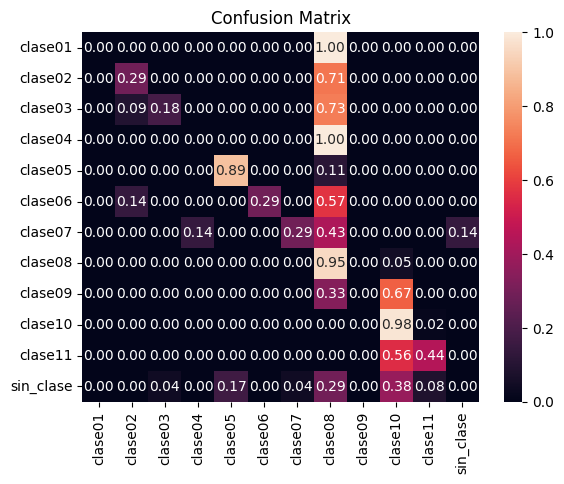

In [9]:
# Evaluacion final
resultado_test = validar_modelo(
    modelo=model,
    loader=test_loader,
    criterio=criterion,
    dispositivo=DEVICE,
)
print(f"Test Acc: {resultado_test.accuracy:.4f}")

final_preds = resultado_test.predicciones
final_labels = resultado_test.etiquetas
all_label_ids = list(range(NUM_CLASSES))

print(
    classification_report(
        final_labels,
        final_preds,
        labels=all_label_ids,
        target_names=class_names,
        zero_division=0,
    )
)

cm = confusion_matrix(final_labels, final_preds, labels=all_label_ids, normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.show()

In [10]:
# 9. Guardado del modelo
torch.save(model.state_dict(), PATHS.OUTPUT_MODELS / f"{MODEL_NAME}_final.pth")